
# 04 — Calibration and Evaluation

## Project: Evaluating Low-Cost PM2.5 Sensors: Calibration Accuracy, Generalization, and Reliability

### 1. Purpose of This Notebook

This notebook develops and evaluates calibration models for low-cost PurpleAir PM2.5 measurements using the EPA 24-hour collocation dataset.

It builds on the data profiling, analytical decisions, and exploratory findings documented in:

- `01_data_profile.ipynb`
- `02_analytical_decisions.ipynb`
- `03_exploratory_data_analysis.ipynb`

The primary objective is to determine whether calibration improves agreement between PurpleAir measurements and reference-monitor PM2.5 concentrations, particularly when evaluated on sites that were not used during model training.

### 2. Research Question

How much does calibration improve agreement between low-cost PurpleAir sensors and reference monitors, and does the improvement generalize to previously unseen sites?

### 3. Modeling Scope

Dataset A — 24-Hour Collocation will be used for the initial calibration experiments.

Dataset B — Hourly Wildfire-Smoke Observations will remain a separate evaluation setting and will not be mixed with Dataset A during model training.

### 4. Initial Modeling Framework

- Target variable: `PM25FM`
- Raw PurpleAir predictors: `PM25cf1` and `PM25cfatm`
- Environmental predictors under consideration: `RH` and `TempC`
- Baselines: Uncorrected CF=1 and CF=ATM measurements
- Validation strategy: Site-grouped holdout
- Primary evaluation metric: Mean Absolute Error (MAE), in µg/m³
- Supporting metrics: RMSE, mean bias, and R²

All preprocessing, feature transformations, and model fitting decisions will be learned using training data only. The held-out sites will remain untouched until final evaluation.


In [13]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:

# 1. Setup and Data Loading

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_STATE = 42

# Find the project root from the notebook's current directory.
current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "data" / "raw").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook "
        "from inside the low-cost-pm25-calibration repository."
    )

# Define project directories
RAW_DIR = PROJECT_ROOT / "data" / "raw"

COLLOCATION_DIR = RAW_DIR / "24hr_collocation"
SMOKE_DIR = RAW_DIR / "hourly_smoke"

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Ensure output directories exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Define source files
COLLOCATION_FILE = (
    COLLOCATION_DIR / "Full24hrdataset.csv"
)

SMOKE_FILE = (
    SMOKE_DIR
    / "Finaldataset_correcteddatasetwholding_10_26_22.csv"
)

# Verify source files
required_files = {
    "24-hour collocation dataset": COLLOCATION_FILE,
    "Hourly wildfire-smoke dataset": SMOKE_FILE,
}

for dataset_name, file_path in required_files.items():

    if not file_path.is_file():
        raise FileNotFoundError(
            f"{dataset_name} is missing: {file_path}"
        )

    print(
        f"{dataset_name}: available "
        f"({file_path.stat().st_size:,} bytes)"
    )

# Load both original datasets
df_24hr = pd.read_csv(
    COLLOCATION_FILE,
    low_memory=False
)

df_smoke = pd.read_csv(
    SMOKE_FILE,
    low_memory=False
)

# Display dataset dimensions
print("\nDataset A — 24-Hour Collocation")
print(f"Rows: {len(df_24hr):,}")
print(f"Columns: {df_24hr.shape[1]:,}")

print("\nDataset B — Hourly Wildfire Smoke")
print(f"Rows: {len(df_smoke):,}")
print(f"Columns: {df_smoke.shape[1]:,}")

print("\nProject root:", PROJECT_ROOT)


24-hour collocation dataset: available (6,420,524 bytes)
Hourly wildfire-smoke dataset: available (261,969,901 bytes)

Dataset A — 24-Hour Collocation
Rows: 12,430
Columns: 31

Dataset B — Hourly Wildfire Smoke
Rows: 1,513,776
Columns: 13

Project root: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration



## 2. Dataset A — Modeling Data Validation

Before model development, the 24-hour collocation dataset is examined to verify its structure, site coverage, missing values, and repeated observations.

The EDA identified repeated site-date-region combinations. These observations will be investigated rather than automatically removed because they may represent multiple reference-monitor records.

The purpose of this section is to establish the eligible observations and preserve the grouping structure required for site-based validation.

No observations are removed or modified in this section.


In [2]:

# 2.1 Inspect Dataset A structure

print("Dataset dimensions:", df_24hr.shape)

print("\nColumn names:")
print(df_24hr.columns.tolist())

print("\nData types:")
display(df_24hr.dtypes.to_frame("Data_Type"))

# Verify required modeling and grouping columns
required_columns = [
    "ID",
    "Date",
    "region",
    "PM25FM",
    "PM25cf1",
    "PM25cfatm",
    "RH",
    "TempC",
    "Dewpoint"
]

missing_columns = [
    col for col in required_columns
    if col not in df_24hr.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("\nAll required columns are present.")


Dataset dimensions: (12430, 31)

Column names:
['Unnamed: 0', 'Date', 'ID', 'region', 'FEMorFRM', 'FEMorFRMtype', 'PM25FM', 'PM25cfatm', 'PM25cf1', 'b0.3um', 'b0.5um', 'b1um', 'b2.5um', 'b5um', 'b10um', 'b0.3to0.5', 'b0.5to1', 'b1to2.5', 'b2.5to5', 'b5to10', 'TempC', 'RH', 'Dewpoint', 'PM25PAlinearcor', 'PM25PARHcor', 'ratioPARHcor_FM', 'diffPARHcor_FM', 'ratiocfatm_FM', 'diffcfatm_FM', 'ratiocf1_FM', 'diffcf1_FM']

Data types:


,Data_Type
Unnamed: 0,int64
Date,str
ID,str
region,str
FEMorFRM,str
FEMorFRMtype,str
PM25FM,float64
PM25cfatm,float64
PM25cf1,float64
b0.3um,float64



All required columns are present.


In [3]:

# 2.2 Examine site and date coverage

print("Unique sites:", df_24hr["ID"].nunique())
print("Unique regions:", df_24hr["region"].nunique())

print("\nObservations per site:")
site_observation_counts = (
    df_24hr.groupby("ID")
    .size()
    .sort_values(ascending=False)
)

display(
    site_observation_counts
    .describe()
    .to_frame("Observations_Per_Site")
)

print("\nObservations by region:")
display(
    df_24hr.groupby("region")
    .size()
    .sort_values(ascending=False)
    .to_frame("Observations")
)

# Parse dates into a separate variable
modeling_dates = pd.to_datetime(
    df_24hr["Date"],
    errors="coerce"
)

print("\nDate coverage:")
print("Earliest:", modeling_dates.min())
print("Latest:", modeling_dates.max())
print("Unparseable dates:", modeling_dates.isna().sum())


Unique sites: 49
Unique regions: 5

Observations per site:


,Observations_Per_Site
count,49.000000
mean,253.673469
std,207.136669
min,3.000000
25%,111.000000
50%,184.000000
75%,384.000000
max,830.000000



Observations by region:


,Observations
region,
North,5762
West,3762
Central Southwest,1504
Southeast,1033
Alaska,369



Date coverage:
Earliest: 2017-09-30 00:00:00
Latest: 2020-01-13 00:00:00
Unparseable dates: 0


In [4]:

# 2.3 Recheck missingness and repeated observations

modeling_columns = [
    "ID",
    "Date",
    "region",
    "PM25FM",
    "PM25cf1",
    "PM25cfatm",
    "RH",
    "TempC",
    "Dewpoint"
]

missingness_summary = pd.DataFrame({
    "Missing_Count": df_24hr[modeling_columns].isna().sum(),
    "Missing_Percent": (
        df_24hr[modeling_columns].isna().mean() * 100
    )
})

display(missingness_summary.round(3))

# Examine repeated site-date-region combinations
group_columns = ["ID", "Date", "region"]

site_date_counts = (
    df_24hr.groupby(group_columns, dropna=False)
    .size()
    .rename("Records")
    .reset_index()
)

repeated_combinations = site_date_counts[
    site_date_counts["Records"] > 1
]

print(
    "\nRepeated site-date-region combinations:",
    len(repeated_combinations)
)

print(
    "Rows belonging to repeated combinations:",
    repeated_combinations["Records"].sum()
)

print(
    "\nNonpositive reference measurements:",
    (df_24hr["PM25FM"] <= 0).sum()
)

print(
    "Exact duplicate rows:",
    df_24hr.duplicated().sum()
)


,Missing_Count,Missing_Percent
ID,0,0.000
Date,0,0.000
region,0,0.000
PM25FM,0,0.000
PM25cf1,0,0.000
PM25cfatm,0,0.000
RH,17,0.137
TempC,184,1.480
Dewpoint,184,1.480



Repeated site-date-region combinations: 2199
Rows belonging to repeated combinations: 4922

Nonpositive reference measurements: 44
Exact duplicate rows: 0



## 2.4 Investigating Repeated Observations and Site Coverage

The EDA identified 2,199 repeated site-date-region combinations, affecting 4,922 rows.

These records are retained until their structure is understood. We examine whether repeated combinations contain different reference-monitor methods or measurement values.

We also examine the number of observations and regional representation for each site before constructing a site-grouped holdout.


In [5]:

# 2.4.1 Examine repeated site-date-region combinations

group_columns = ["ID", "Date", "region"]

repeated_group_details = (
    df_24hr.groupby(group_columns, dropna=False)
    .agg(
        Records=("PM25FM", "size"),
        Unique_Reference_Values=("PM25FM", "nunique"),
        Unique_CF1_Values=("PM25cf1", "nunique"),
        Unique_CFATM_Values=("PM25cfatm", "nunique"),
        Reference_Methods=("FEMorFRM", "nunique"),
        Reference_Method_Types=("FEMorFRMtype", "nunique")
    )
    .reset_index()
)

repeated_group_details = repeated_group_details[
    repeated_group_details["Records"] > 1
].sort_values("Records", ascending=False)

print("Repeated combinations:", len(repeated_group_details))

print("\nDistribution of records per repeated combination:")
display(
    repeated_group_details["Records"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Combinations")
)

print("\nRepeated combinations with different reference values:")
display(
    repeated_group_details[
        repeated_group_details["Unique_Reference_Values"] > 1
    ].head(15)
)

print("\nSample of repeated combinations:")
display(repeated_group_details.head(15))


Repeated combinations: 2199

Distribution of records per repeated combination:


,Number_of_Combinations
Records,
2,1718
3,438
4,43



Repeated combinations with different reference values:


,ID,Date,region,Records,Unique_Reference_Values,Unique_CF1_Values,Unique_CFATM_Values,Reference_Methods,Reference_Method_Types
5191,IA11,2019-02-20,North,4,4,1,1,2,2
6227,IA3,2019-07-08,North,4,3,1,1,2,2
5974,IA3,2018-05-02,North,4,4,1,1,2,2
5030,IA1,2019-11-17,North,4,4,1,1,2,3
6336,IA4,2019-02-02,North,4,3,1,1,2,2
6147,IA3,2019-02-20,North,4,4,1,1,2,2
5610,IA2,2019-02-02,North,4,4,1,1,2,2
5564,IA2,2018-11-22,North,4,4,1,1,2,2
5071,IA10,2019-02-02,North,4,4,1,1,2,2
5575,IA2,2018-12-10,North,4,4,1,1,2,2



Sample of repeated combinations:


,ID,Date,region,Records,Unique_Reference_Values,Unique_CF1_Values,Unique_CFATM_Values,Reference_Methods,Reference_Method_Types
5191,IA11,2019-02-20,North,4,4,1,1,2,2
6227,IA3,2019-07-08,North,4,3,1,1,2,2
5974,IA3,2018-05-02,North,4,4,1,1,2,2
5030,IA1,2019-11-17,North,4,4,1,1,2,3
6336,IA4,2019-02-02,North,4,3,1,1,2,2
6147,IA3,2019-02-20,North,4,4,1,1,2,2
5610,IA2,2019-02-02,North,4,4,1,1,2,2
5564,IA2,2018-11-22,North,4,4,1,1,2,2
5071,IA10,2019-02-02,North,4,4,1,1,2,2
5575,IA2,2018-12-10,North,4,4,1,1,2,2


In [6]:

# 2.4.2 Examine site-level coverage and regional assignments

site_profile = (
    df_24hr.groupby("ID")
    .agg(
        Observations=("ID", "size"),
        Regions=("region", "nunique"),
        Region=("region", "first"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max")
    )
    .sort_values("Observations", ascending=False)
)

print("Site-level profile:")
display(site_profile)

print("\nSites assigned to multiple regions:")
display(site_profile[site_profile["Regions"] > 1])

print("\nNumber of sites per region:")
display(
    df_24hr.groupby("region")["ID"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("Number_of_Sites")
)


Site-level profile:


,Observations,Regions,Region,First_Date,Last_Date
ID,,,,,
IA3,830,1,North,2017-09-30,2020-01-11
NC4,700,1,Southeast,2018-03-25,2019-10-24
CA2,659,1,West,2017-11-29,2019-10-23
IA2,646,1,North,2018-05-09,2020-01-13
CA13,619,1,West,2018-03-22,2019-07-24
IA1,603,1,North,2018-04-30,2020-01-13
WA1,561,1,North,2017-10-16,2019-10-28
WI2,450,1,North,2019-01-06,2019-10-24
AZ4,435,1,Central Southwest,2018-11-09,2019-12-31



Sites assigned to multiple regions:


,Observations,Regions,Region,First_Date,Last_Date
ID,,,,,



Number of sites per region:


,Number_of_Sites
region,
North,20
West,13
Central Southwest,9
Southeast,4
Alaska,3


In [7]:

# 2.4.3 Inspect reference-monitor method distribution

print("Reference-monitor method counts:")
display(
    df_24hr["FEMorFRM"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nReference-monitor method type counts:")
display(
    df_24hr["FEMorFRMtype"]
    .value_counts(dropna=False)
    .to_frame("Count")
)


Reference-monitor method counts:


,Count
FEMorFRM,
FEM,10087
FRM,2343



Reference-monitor method type counts:


,Count
FEMorFRMtype,
Met One BAM-1020 Mass Monitor w/VSCC - Beta Attenuation,4746
Teledyne T640 at 5.0 LPM - Broadband spectroscopy,2382
R & P Model 2025 PM-2.5 Sequential Air Sampler w/VSCC - Gravimetric,2255
Thermo Scientific TEOM 1405-DF Dichotomous FDMS - FDMS Gravimetric,862
Teledyne T640X at 16.67 LPM - Broadband spectroscopy,760
Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM2.5C - Beta Attenuation,718
Thermo Scientific 1405-F FDMS w/VSCC - FDMS Gravimetric,384
Thermo Scientific TEOM 1400 FDMS or 1405 8500C FDMS w/VSCC - FDMS Gravimetric,235
R & P Model 2000 PM-2.5 Air Sampler w/VSCC - Gravimetric,88



## 3. Modeling Dataset Preparation

This section creates a separate modeling dataframe from the original 24-hour collocation dataset.

The original observations are retained as paired PurpleAir and reference-monitor measurements. Repeated site-date records are not automatically removed or averaged because repeated records can contain distinct reference-monitor measurements.

The modeling dataset preserves the site identifier for group-based validation.

The target is `PM25FM`. Raw PurpleAir measurements (`PM25cf1` and `PM25cfatm`) are retained as baseline predictors. Environmental predictors will be incorporated through separate calibration models.

Pre-existing corrected outputs and derived error columns are excluded from the new model features to prevent information leakage.


In [8]:

# 3.1 Create the modeling dataframe

model_columns = [
    "ID",
    "Date",
    "region",
    "FEMorFRM",
    "FEMorFRMtype",
    "PM25FM",
    "PM25cf1",
    "PM25cfatm",
    "RH",
    "TempC",
    "Dewpoint"
]

model_df = df_24hr[model_columns].copy()

# Convert Date to datetime
model_df["Date"] = pd.to_datetime(
    model_df["Date"],
    errors="coerce"
)

# Keep the original row index for traceability
model_df["source_row"] = df_24hr.index

print("Modeling dataframe shape:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

display(model_df.head())


Modeling dataframe shape: (12430, 12)

Columns:
['ID', 'Date', 'region', 'FEMorFRM', 'FEMorFRMtype', 'PM25FM', 'PM25cf1', 'PM25cfatm', 'RH', 'TempC', 'Dewpoint', 'source_row']


,ID,Date,region,FEMorFRM,FEMorFRMtype,PM25FM,PM25cf1,PM25cfatm,RH,TempC,Dewpoint,source_row
0,AK1,2019-05-17,Alaska,FRM,R & P Model 2025 PM-2.5 Sequential Air Sampler...,6.7,8.616954,8.257688,38.564815,18.027263,3.629662,0
1,AK1,2019-05-18,Alaska,FRM,R & P Model 2025 PM-2.5 Sequential Air Sampler...,3.8,3.493916,3.359005,49.404315,16.115280,5.442318,1
2,AK1,2019-05-21,Alaska,FRM,R & P Model 2025 PM-2.5 Sequential Air Sampler...,4.0,3.799601,3.799601,29.972222,19.897634,1.734051,2
3,AK1,2019-05-22,Alaska,FRM,R & P Model 2025 PM-2.5 Sequential Air Sampler...,4.7,4.369691,4.369691,32.474513,21.378334,4.165624,3
4,AK1,2019-05-19,Alaska,FRM,R & P Model 2025 PM-2.5 Sequential Air Sampler...,3.2,3.191071,3.191071,43.898226,18.443822,5.867611,4


In [9]:

# 3.2 Check target and predictor eligibility

required_numeric = [
    "PM25FM",
    "PM25cf1",
    "PM25cfatm"
]

eligibility_summary = pd.DataFrame({
    "Missing": model_df[required_numeric].isna().sum(),
    "Non_Finite": [
        (~np.isfinite(model_df[col].dropna())).sum()
        for col in required_numeric
    ],
    "Minimum": model_df[required_numeric].min(),
    "Maximum": model_df[required_numeric].max()
})

display(eligibility_summary)

print(
    "\nNonpositive reference measurements:",
    (model_df["PM25FM"] <= 0).sum()
)

print(
    "Missing RH:",
    model_df["RH"].isna().sum()
)

print(
    "Missing temperature:",
    model_df["TempC"].isna().sum()
)


,Missing,Non_Finite,Minimum,Maximum
PM25FM,0,0,-1.777778,108.800000
PM25cf1,0,0,0.181708,256.309609
PM25cfatm,0,0,0.181708,169.907631



Nonpositive reference measurements: 44
Missing RH: 17
Missing temperature: 184


In [10]:

# 3.3 Select observations with valid paired measurements

baseline_columns = [
    "ID",
    "Date",
    "region",
    "PM25FM",
    "PM25cf1",
    "PM25cfatm",
    "source_row"
]

baseline_df = model_df[baseline_columns].copy()

baseline_df = baseline_df.replace(
    [np.inf, -np.inf],
    np.nan
)

baseline_df = baseline_df.dropna(
    subset=[
        "ID",
        "PM25FM",
        "PM25cf1",
        "PM25cfatm"
    ]
).copy()

print("Original observations:", len(model_df))
print("Valid paired observations:", len(baseline_df))
print("Excluded observations:", len(model_df) - len(baseline_df))

print("\nUnique sites:", baseline_df["ID"].nunique())
print("Repeated site-date-region records are retained.")

print(
    "\nNonpositive reference measurements retained:",
    (baseline_df["PM25FM"] <= 0).sum()
)


Original observations: 12430
Valid paired observations: 12430
Excluded observations: 0

Unique sites: 49
Repeated site-date-region records are retained.

Nonpositive reference measurements retained: 44


In [11]:

# 3.4 Check availability of environmental predictors

environmental_columns = ["RH", "TempC", "Dewpoint"]

environmental_availability = pd.DataFrame({
    "Available": model_df[environmental_columns].notna().sum(),
    "Missing": model_df[environmental_columns].isna().sum(),
    "Missing_Percent": (
        model_df[environmental_columns].isna().mean() * 100
    )
})

display(environmental_availability.round(3))


,Available,Missing,Missing_Percent
RH,12413,17,0.137
TempC,12246,184,1.480
Dewpoint,12246,184,1.480



## 4. Site-Grouped Train/Test Split

The primary evaluation objective is generalization to previously unseen monitoring sites.

Therefore, observations are split by site identifier (`ID`) rather than randomly by individual rows.

Approximately 80% of sites are assigned to training and 20% to testing. The site-level split is stratified by region to improve regional representation in the holdout.

All observations belonging to a selected site remain together in one partition. This prevents measurements from the same site from appearing in both training and testing.

The test sites are reserved for final model evaluation and are not used for model fitting, preprocessing, or model selection.


In [17]:
# 4.1 Create a reproducible site-level split
from sklearn.model_selection import train_test_split

site_table = (
    baseline_df[["ID", "region"]]
    .drop_duplicates()
    .sort_values("ID")
    .reset_index(drop=True)
)

train_site_ids = set()
test_site_ids = set()

for region, group in site_table.groupby("region"):
    n_test = max(1, round(len(group) * 0.20))

    region_train, region_test = train_test_split(
        group,
        test_size=n_test,
        random_state=RANDOM_STATE
    )

    train_site_ids.update(region_train["ID"])
    test_site_ids.update(region_test["ID"])

print("Training sites:", len(train_site_ids))
print("Testing sites:", len(test_site_ids))
print("Overlapping sites:", train_site_ids & test_site_ids)

Training sites: 38
Testing sites: 11
Overlapping sites: set()


In [18]:
train_df = baseline_df[baseline_df["ID"].isin(train_site_ids)].copy()
test_df = baseline_df[baseline_df["ID"].isin(test_site_ids)].copy()

assert len(train_df) + len(test_df) == len(baseline_df)
assert train_site_ids.isdisjoint(test_site_ids)

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining distribution:")
display(
    train_df.groupby("region").agg(
        Observations=("ID", "size"),
        Sites=("ID", "nunique")
    )
)

print("\nTesting distribution:")
display(
    test_df.groupby("region").agg(
        Observations=("ID", "size"),
        Sites=("ID", "nunique")
    )
)

print("\nHeld-out sites:")
display(
    test_df.groupby(["ID", "region"])
    .size()
    .rename("Observations")
    .reset_index()
    .sort_values("region")
)

Training observations: 9529
Testing observations: 2901

Training distribution:


,Observations,Sites
region,,
Alaska,243,2
Central Southwest,1000,7
North,4347,16
Southeast,849,3
West,3090,10



Testing distribution:


,Observations,Sites
region,,
Alaska,126,1
Central Southwest,504,2
North,1415,4
Southeast,184,1
West,672,3



Held-out sites:


,ID,region,Observations
0,AK1,Alaska,126
1,AZ3,Central Southwest,384
8,OK1,Central Southwest,120
6,IA1,North,603
7,IA10,North,177
9,WI2,North,450
10,WI4,North,185
5,GA1,Southeast,184
2,CA1,West,161
3,CA3,West,265


In [20]:
# Save the finalized site-level split
split_df = site_table.copy()

split_df["split"] = split_df["ID"].apply(
    lambda site: "test" if site in test_site_ids else "train"
)

split_path = PROCESSED_DIR / "site_grouped_train_test_split.csv"
split_df.to_csv(split_path, index=False)

print("Saved split to:", split_path)
print(split_df["split"].value_counts())

Saved split to: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/site_grouped_train_test_split.csv
split
train    38
test     11
Name: count, dtype: int64


In [21]:
# 5.1 Evaluate raw PurpleAir baselines on the test set

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true = test_df["PM25FM"]

baseline_results = []

for column, label in [
    ("PM25cf1", "CF=1"),
    ("PM25cfatm", "CF=ATM")
]:
    y_pred = test_df[column]

    baseline_results.append({
        "Baseline": label,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Mean_Bias": np.mean(y_pred - y_true),
        "R2": r2_score(y_true, y_pred)
    })

baseline_metrics = pd.DataFrame(baseline_results)

display(baseline_metrics.round(3))

,Baseline,MAE,RMSE,Mean_Bias,R2
0,CF=1,5.938,9.204,4.909,-1.579
1,CF=ATM,5.337,7.508,4.298,-0.716


In [22]:
# 5.2 Compare raw baseline performance by held-out site

site_baseline_metrics = (
    test_df.groupby(["ID", "region"])
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),
            "CF1_MAE": mean_absolute_error(
                group["PM25FM"], group["PM25cf1"]
            ),
            "CFATM_MAE": mean_absolute_error(
                group["PM25FM"], group["PM25cfatm"]
            ),
            "CF1_Bias": (
                group["PM25cf1"] - group["PM25FM"]
            ).mean(),
            "CFATM_Bias": (
                group["PM25cfatm"] - group["PM25FM"]
            ).mean()
        }),
        include_groups=False
    )
    .reset_index()
)

site_baseline_metrics["MAE_Improvement"] = (
    site_baseline_metrics["CF1_MAE"]
    - site_baseline_metrics["CFATM_MAE"]
)

display(site_baseline_metrics.round(3))

print(
    "Sites where CF=ATM has lower MAE:",
    (site_baseline_metrics["MAE_Improvement"] > 0).sum(),
    "out of",
    len(site_baseline_metrics)
)

print(
    "Equal-site average MAE:",
    "\nCF=1:", round(site_baseline_metrics["CF1_MAE"].mean(), 3),
    "\nCF=ATM:", round(site_baseline_metrics["CFATM_MAE"].mean(), 3)
)

,ID,region,Observations,CF1_MAE,CFATM_MAE,CF1_Bias,CFATM_Bias,MAE_Improvement
0,AK1,Alaska,126.0,4.578,2.851,3.890,2.154,1.726
1,AZ3,Central Southwest,384.0,4.241,3.616,0.486,-0.182,0.626
2,CA1,West,161.0,6.519,5.024,4.617,3.114,1.495
3,CA3,West,265.0,3.715,3.625,3.388,3.288,0.090
4,CA5,West,246.0,3.231,3.195,2.174,2.116,0.037
5,GA1,Southeast,184.0,6.871,6.624,6.751,6.504,0.247
6,IA1,North,603.0,9.230,8.474,8.932,8.173,0.756
7,IA10,North,177.0,11.686,10.345,11.460,10.114,1.342
8,OK1,Central Southwest,120.0,2.503,2.438,0.334,0.264,0.065
9,WI2,North,450.0,4.458,4.025,4.034,3.599,0.432


Sites where CF=ATM has lower MAE: 11 out of 11
Equal-site average MAE: 
CF=1: 5.669 
CF=ATM: 5.016


### Raw Baseline Evaluation — Unseen-Site Holdout

The site-grouped holdout contained 2,901 observations from 11 sites across all five regions. No site appeared in both training and testing data.

The uncalibrated CF=ATM channel outperformed CF=1 on the holdout. CF=ATM achieved an observation-weighted MAE of 5.337 µg/m³ and RMSE of 7.508 µg/m³, compared with 5.938 µg/m³ and 9.204 µg/m³ for CF=1. Its mean bias was also closer to zero (+4.298 versus +4.909 µg/m³).

The site-level comparison supported this result: CF=ATM had lower MAE at all 11 held-out sites. Its equal-site average MAE was 5.016 µg/m³, compared with 5.669 µg/m³ for CF=1.

Therefore, CF=ATM is selected as the primary raw baseline for subsequent calibration evaluation. Both raw channels will remain comparison benchmarks. The consistently positive bias indicates that overestimation remains an important calibration issue.

In [24]:
# Reconstruct modeling datasets using the finalized site split

train_model_df = model_df[
    model_df["ID"].isin(train_site_ids)
].copy()

test_model_df = model_df[
    model_df["ID"].isin(test_site_ids)
].copy()

print("Training modeling data:", train_model_df.shape)
print("Testing modeling data:", test_model_df.shape)

print("\nTraining missing values:")
display(train_model_df[["PM25cfatm", "RH"]].isna().sum())

print("\nTesting missing values:")
display(test_model_df[["PM25cfatm", "RH"]].isna().sum())

# Validate the site separation
assert set(train_model_df["ID"]).isdisjoint(
    set(test_model_df["ID"])
)

print("\nSite separation validated.")

Training modeling data: (9529, 12)
Testing modeling data: (2901, 12)

Training missing values:


PM25cfatm     0
RH           14
dtype: int64


Testing missing values:


PM25cfatm    0
RH           3
dtype: int64


Site separation validated.


In [25]:
# 6.2 Build and train calibration models

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

# Define predictors and target
X_train_simple = train_model_df[["PM25cfatm"]]
X_train_humidity = train_model_df[["PM25cfatm", "RH"]]

y_train = train_model_df["PM25FM"]

# Model 1: Simple linear calibration
simple_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

# Model 2: Humidity-aware linear calibration
humidity_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

# Fit using training data only
simple_model.fit(X_train_simple, y_train)
humidity_model.fit(X_train_humidity, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [26]:
# 6.3 Inspect fitted model coefficients

simple_reg = simple_model.named_steps["regression"]
humidity_reg = humidity_model.named_steps["regression"]

print("SIMPLE LINEAR CALIBRATION")
print("Intercept:", simple_reg.intercept_)
print("PM25cfatm coefficient:", simple_reg.coef_[0])

print("\nHUMIDITY-AWARE CALIBRATION")
print("Intercept:", humidity_reg.intercept_)
print("PM25cfatm coefficient:", humidity_reg.coef_[0])
print("RH coefficient:", humidity_reg.coef_[1])

SIMPLE LINEAR CALIBRATION
Intercept: 2.7292389383096625
PM25cfatm coefficient: 0.45301901895618907

HUMIDITY-AWARE CALIBRATION
Intercept: 5.8517441435564646
PM25cfatm coefficient: 0.48586935855032093
RH coefficient: -0.07176975154803436


In [27]:
# 7.1 Generate predictions on the untouched test set

X_test_simple = test_model_df[["PM25cfatm"]]
X_test_humidity = test_model_df[["PM25cfatm", "RH"]]

y_test = test_model_df["PM25FM"]

# Predictions from calibrated models
simple_predictions = simple_model.predict(X_test_simple)
humidity_predictions = humidity_model.predict(X_test_humidity)

print("Predictions generated successfully.")
print("Test observations:", len(y_test))
print("Simple model predictions:", len(simple_predictions))
print("Humidity model predictions:", len(humidity_predictions))

Predictions generated successfully.
Test observations: 2901
Simple model predictions: 2901
Humidity model predictions: 2901


In [28]:
# 7.2 Compare raw baselines and calibrated models

model_predictions = {
    "Raw CF=1": test_model_df["PM25cf1"].to_numpy(),
    "Raw CF=ATM": test_model_df["PM25cfatm"].to_numpy(),
    "Simple linear calibration": simple_predictions,
    "Humidity-aware calibration": humidity_predictions
}

evaluation_results = []

for model_name, predictions in model_predictions.items():
    evaluation_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Mean_Bias": np.mean(predictions - y_test),
        "R2": r2_score(y_test, predictions)
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(3))

,Model,MAE,RMSE,Mean_Bias,R2
0,Raw CF=1,5.938,9.204,4.909,-1.579
1,Raw CF=ATM,5.337,7.508,4.298,-0.716
2,Simple linear calibration,1.826,2.581,0.000,0.797
3,Humidity-aware calibration,1.556,2.249,0.044,0.846


### Calibration Model Evaluation — Unseen-Site Holdout

Both calibrated models substantially outperformed the raw PurpleAir baselines on the 2,901-observation holdout containing 11 entirely unseen sites across five regions.

The simple linear calibration model, using PM25cfatm as its predictor, achieved an MAE of 1.826 µg/m³, RMSE of 2.581 µg/m³, and R² of 0.797.

The humidity-aware linear model, using PM25cfatm and RH, achieved an MAE of 1.556 µg/m³, RMSE of 2.249 µg/m³, and R² of 0.846. Its mean bias was +0.044 µg/m³.

Compared with the raw CF=ATM baseline (MAE 5.337 µg/m³), the humidity-aware model reduced MAE by approximately 70.8%. It also improved MAE by approximately 14.8% relative to simple linear calibration.

The humidity-aware model is the leading candidate because it achieved the lowest MAE and RMSE and the highest R² on the unseen-site holdout. These results indicate that adding relative humidity provides predictive value beyond the raw CF=ATM measurement in this evaluation.

In [29]:
# 7.3 Evaluate model performance by held-out site

site_predictions = test_model_df[
    ["ID", "region", "PM25FM", "PM25cf1", "PM25cfatm"]
].copy()

site_predictions["Simple_Calibrated"] = simple_predictions
site_predictions["Humidity_Calibrated"] = humidity_predictions

site_results = (
    site_predictions.groupby(["ID", "region"])
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),
            "Raw_CFATM_MAE": mean_absolute_error(
                group["PM25FM"], group["PM25cfatm"]
            ),
            "Simple_MAE": mean_absolute_error(
                group["PM25FM"], group["Simple_Calibrated"]
            ),
            "Humidity_MAE": mean_absolute_error(
                group["PM25FM"], group["Humidity_Calibrated"]
            )
        }),
        include_groups=False
    )
    .reset_index()
)

site_results["Humidity_Improvement"] = (
    site_results["Simple_MAE"] - site_results["Humidity_MAE"]
)

display(site_results.round(3))

print(
    "Sites where humidity-aware model beats simple model:",
    (site_results["Humidity_Improvement"] > 0).sum(),
    "out of", len(site_results)
)

,ID,region,Observations,Raw_CFATM_MAE,Simple_MAE,Humidity_MAE,Humidity_Improvement
0,AK1,Alaska,126.0,2.851,1.510,1.348,0.162
1,AZ3,Central Southwest,384.0,3.616,2.783,1.769,1.014
2,CA1,West,161.0,5.024,1.935,1.621,0.314
3,CA3,West,265.0,3.625,1.888,1.560,0.328
4,CA5,West,246.0,3.195,1.750,1.657,0.093
5,GA1,Southeast,184.0,6.624,1.071,0.844,0.227
6,IA1,North,603.0,8.474,1.934,1.888,0.046
7,IA10,North,177.0,10.345,1.959,1.771,0.188
8,OK1,Central Southwest,120.0,2.438,2.659,2.770,-0.112
9,WI2,North,450.0,4.025,1.068,0.805,0.263


Sites where humidity-aware model beats simple model: 10 out of 11


In [30]:
# 7.4 Summarize performance across held-out sites

site_summary = pd.DataFrame({
    "Model": [
        "Raw CF=ATM",
        "Simple linear calibration",
        "Humidity-aware calibration"
    ],
    "Equal_Site_Average_MAE": [
        site_results["Raw_CFATM_MAE"].mean(),
        site_results["Simple_MAE"].mean(),
        site_results["Humidity_MAE"].mean()
    ],
    "Sites_Better_Than_Raw": [
        0,
        (site_results["Simple_MAE"] < site_results["Raw_CFATM_MAE"]).sum(),
        (site_results["Humidity_MAE"] < site_results["Raw_CFATM_MAE"]).sum()
    ]
})

display(site_summary.round(3))

print(
    "Humidity-aware beats simple:",
    (site_results["Humidity_MAE"] < site_results["Simple_MAE"]).sum(),
    "of", len(site_results), "sites"
)

print(
    "Humidity-aware beats raw CF=ATM:",
    (site_results["Humidity_MAE"] < site_results["Raw_CFATM_MAE"]).sum(),
    "of", len(site_results), "sites"
)

,Model,Equal_Site_Average_MAE,Sites_Better_Than_Raw
0,Raw CF=ATM,5.016,0
1,Simple linear calibration,1.827,10
2,Humidity-aware calibration,1.595,10


Humidity-aware beats simple: 10 of 11 sites
Humidity-aware beats raw CF=ATM: 10 of 11 sites


### Site-Level Calibration Assessment

The humidity-aware calibration model achieved an equal-site average MAE of 1.595 µg/m³, compared with 1.827 µg/m³ for simple linear calibration and 5.016 µg/m³ for raw CF=ATM.

Humidity-aware calibration outperformed simple linear calibration at 10 of 11 held-out sites and outperformed raw CF=ATM at 10 of 11 sites. The exception was OK1, where both calibrated models had higher MAE than the raw measurement.

These results support humidity-aware linear calibration as the leading method on this holdout. However, the OK1 result shows that improvements are not universal across sites. The evaluation uses one fixed site-grouped split, so further validation across alternative site splits is needed before making broader generalization claims.

In [31]:
# 7.5 Post-hoc diagnostic: held-out site OK1

ok1 = site_predictions[
    site_predictions["ID"] == "OK1"
].copy()

print("OK1 observations:", len(ok1))

print("\nPM2.5 reference concentration:")
display(ok1["PM25FM"].describe().round(3))

print("\nPurpleAir CF=ATM:")
display(ok1["PM25cfatm"].describe().round(3))

print("\nRelative humidity:")
display(test_model_df.loc[
    test_model_df["ID"] == "OK1", "RH"
].describe().round(3))

print("\nMissing RH values:")
print(
    test_model_df.loc[
        test_model_df["ID"] == "OK1", "RH"
    ].isna().sum()
)

OK1 observations: 120

PM2.5 reference concentration:


count    120.000
mean       9.848
std        3.615
min        4.500
25%        7.177
50%        9.602
75%       11.344
max       23.275
Name: PM25FM, dtype: float64


PurpleAir CF=ATM:


count    120.000
mean      10.112
std        5.624
min        0.544
25%        6.288
50%        9.224
75%       12.322
max       26.657
Name: PM25cfatm, dtype: float64


Relative humidity:


count    120.000
mean      50.447
std       10.592
min       29.440
25%       41.315
50%       50.831
75%       59.253
max       78.332
Name: RH, dtype: float64


Missing RH values:
0


In [33]:
# 7.6 Compare OK1 predictor ranges with training data

training_stats = train_model_df[
    ["PM25cfatm", "RH"]
].describe().loc[["min", "25%", "50%", "75%", "max"]]

ok1_stats = test_model_df.loc[
    test_model_df["ID"] == "OK1",
    ["PM25cfatm", "RH"]
].describe().loc[["min", "25%", "50%", "75%", "max"]]

comparison = pd.concat(
    {
        "Training": training_stats,
        "OK1": ok1_stats
    },
    axis=1
)

display(comparison.round(3))

Training                OK1        
    PM25cfatm       RH PM25cfatm      RH
min     0.198    1.990     0.544  29.440
25%     4.995   40.583     6.288  41.315
50%     9.484   51.552     9.224  50.831
75%    18.402   60.486    12.322  59.253
max    63.667  100.000    26.657  78.332

### Diagnostic of the OK1 Exception

OK1 was the only held-out site where both calibrated models performed worse than raw CF=ATM. A predictor-range comparison showed that its CF=ATM and RH values fell within the corresponding overall training-data ranges. Their median values were also similar to the training medians.

Therefore, the poorer OK1 performance cannot be explained simply by marginal predictor values falling outside the training ranges. A site-specific calibration relationship or other unmeasured factors may contribute, but the current analysis does not establish the cause.

This exception demonstrates that a pooled calibration model may not improve accuracy at every unseen site.

In [34]:
# 8.1 Five-fold grouped cross-validation on training sites only

from sklearn.model_selection import GroupKFold
from sklearn.base import clone

X_simple = train_model_df[["PM25cfatm"]]
X_humidity = train_model_df[["PM25cfatm", "RH"]]
y = train_model_df["PM25FM"]
groups = train_model_df["ID"]

group_cv = GroupKFold(n_splits=5)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    group_cv.split(X_simple, y, groups=groups), start=1
):
    # Fold-specific training and validation data
    X_simple_train = X_simple.iloc[train_idx]
    X_simple_val = X_simple.iloc[val_idx]

    X_humidity_train = X_humidity.iloc[train_idx]
    X_humidity_val = X_humidity.iloc[val_idx]

    y_train_fold = y.iloc[train_idx]
    y_val_fold = y.iloc[val_idx]

    # Raw CF=ATM baseline
    raw_predictions = X_simple_val["PM25cfatm"].to_numpy()

    # Fit simple linear calibration
    simple_fold_model = clone(simple_model)
    simple_fold_model.fit(X_simple_train, y_train_fold)
    simple_predictions_fold = simple_fold_model.predict(X_simple_val)

    # Fit humidity-aware calibration
    humidity_fold_model = clone(humidity_model)
    humidity_fold_model.fit(X_humidity_train, y_train_fold)
    humidity_predictions_fold = humidity_fold_model.predict(
        X_humidity_val
    )

    predictions_by_model = {
        "Raw CF=ATM": raw_predictions,
        "Simple linear calibration": simple_predictions_fold,
        "Humidity-aware calibration": humidity_predictions_fold
    }

    for model_name, predictions in predictions_by_model.items():
        cv_results.append({
            "Fold": fold,
            "Model": model_name,
            "Validation_Sites": groups.iloc[val_idx].nunique(),
            "Validation_Observations": len(val_idx),
            "MAE": mean_absolute_error(y_val_fold, predictions)
        })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(3))

,Fold,Model,Validation_Sites,Validation_Observations,MAE
0,1,Raw CF=ATM,7,1911,7.406
1,1,Simple linear calibration,7,1911,1.887
2,1,Humidity-aware calibration,7,1911,1.585
3,2,Raw CF=ATM,8,1903,4.496
4,2,Simple linear calibration,8,1903,1.972
5,2,Humidity-aware calibration,8,1903,1.743
6,3,Raw CF=ATM,7,1911,4.510
7,3,Simple linear calibration,7,1911,1.715
8,3,Humidity-aware calibration,7,1911,1.453
9,4,Raw CF=ATM,8,1903,5.857


In [35]:
# 8.2 Summarize grouped cross-validation performance

cv_summary = (
    cv_results_df.groupby("Model")["MAE"]
    .agg(["mean", "std", "min", "max"])
    .rename(columns={
        "mean": "Mean_MAE",
        "std": "Std_MAE",
        "min": "Best_Fold_MAE",
        "max": "Worst_Fold_MAE"
    })
    .sort_values("Mean_MAE")
)

display(cv_summary.round(3))

,Mean_MAE,Std_MAE,Best_Fold_MAE,Worst_Fold_MAE
Model,,,,
Humidity-aware calibration,1.657,0.230,1.453,2.015
Simple linear calibration,1.937,0.179,1.715,2.210
Raw CF=ATM,5.227,1.419,3.865,7.406


### Grouped Cross-Validation Results

Five-fold GroupKFold cross-validation was performed using the 38 training sites. Sites were kept together within each fold to evaluate generalization to unseen locations. The 11-site final test set was not used during cross-validation.

The humidity-aware linear calibration model achieved a mean fold MAE of 1.657 µg/m³ (standard deviation 0.230), outperforming simple linear calibration (mean MAE 1.937, standard deviation 0.179) and raw CF=ATM (mean MAE 5.227, standard deviation 1.419).

Humidity-aware calibration achieved lower MAE than simple linear calibration in all five folds. Its mean MAE was approximately 14.5% lower than simple calibration and 68.3% lower than raw CF=ATM.

These results support selecting humidity-aware linear regression as the primary calibration method, with simple linear calibration as the named alternative. The fold results demonstrate consistent improvement under this grouped validation design, although the folds were not stratified by region.

In [36]:
# Save grouped cross-validation results

cv_results_path = PROCESSED_DIR / "grouped_cv_results.csv"
cv_summary_path = PROCESSED_DIR / "grouped_cv_summary.csv"

cv_results_df.to_csv(cv_results_path, index=False)
cv_summary.to_csv(cv_summary_path)

print("Saved:", cv_results_path)
print("Saved:", cv_summary_path)

Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/grouped_cv_results.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/grouped_cv_summary.csv



## 6. Dataset B: Hourly Wildfire-Smoke Evaluation

The Dataset A calibration models and grouped cross-validation are complete. This section moves to Dataset B, the EPA hourly wildfire-smoke dataset, to evaluate the performance of the existing PurpleAir adjustment configurations (A–F) under the LOBD and LOSO withholding approaches.

Unlike Dataset A, Dataset B contains multiple adjustment and withholding variants for the same underlying city-sensor-hour observation. These related records must be handled carefully to prevent data leakage during evaluation.

The analysis will compare the adjustment configurations against the reference measurements using appropriate error metrics and examine whether performance differs between the two withholding approaches.


In [37]:
print("Dataset B shape:", df_smoke.shape)
print("\nColumns:")
print(df_smoke.columns.tolist())

print("\nCategorical columns and their values:")
for col in df_smoke.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{col}:")
    print(df_smoke[col].value_counts(dropna=False).head(20))

Dataset B shape: (1513776, 13)

Columns:
['Unnamed: 0', 'hr', 'city', 'id', 'RH', 'PA', 'ref', 'monitortype', 'State', 'week', 'adj', 'adjtype', 'wholdtype']

Categorical columns and their values:

hr:
hr
2020-08-31 04:00:00    168
2020-08-31 06:00:00    168
2020-08-31 07:00:00    168
2020-08-31 08:00:00    168
2020-08-31 19:00:00    168
2020-08-26 20:00:00    168
2020-08-27 04:00:00    168
2020-08-27 05:00:00    168
2020-08-27 06:00:00    168
2020-08-27 07:00:00    168
2020-08-27 08:00:00    168
2020-08-27 10:00:00    168
2020-08-27 19:00:00    168
2020-08-27 20:00:00    168
2020-08-28 04:00:00    168
2020-08-28 05:00:00    168
2020-08-28 06:00:00    168
2020-08-28 07:00:00    168
2020-08-28 20:00:00    168
2020-08-29 04:00:00    168
Name: count, dtype: int64

city:
city
Cedar Rapids    234084
Atascadero      202320
Marysville      126180
Sarasota        109740
Denver          105936
Appleton        104664
Topeka           99372
Edmond           98088
Decatur          82416
Wilmington

/var/folders/fv/lzcypv897lq16q7xg0v131x80000gn/T/ipykernel_4248/3389304631.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_smoke.select_dtypes(include=["object", "category"]).columns:


In [38]:

# Check adjustment and withholding categories
print("Adjustment types:")
print(df_smoke["adjtype"].value_counts(dropna=False).sort_index())

print("\nWithholding types:")
print(df_smoke["wholdtype"].value_counts(dropna=False))

print("\nRows by adjustment and withholding type:")
print(
    pd.crosstab(
        df_smoke["adjtype"],
        df_smoke["wholdtype"],
        dropna=False
    )
)

# Verify the underlying observation key
observation_key = ["city", "id", "hr"]

print("\nUnique city-sensor-hour observations:")
print(df_smoke[observation_key].drop_duplicates().shape[0])

print("\nNumber of rows per underlying observation:")
print(
    df_smoke.groupby(observation_key, dropna=False)
    .size()
    .value_counts()
    .sort_index()
)

# Check whether each observation has unique configuration combinations
print("\nDuplicate observation-configuration combinations:")
print(
    df_smoke.duplicated(
        observation_key + ["adjtype", "wholdtype"]
    ).sum()
)


Adjustment types:
adjtype
A    252296
B    252296
C    252296
D    252296
E    252296
F    252296
Name: count, dtype: int64

Withholding types:
wholdtype
LOBD    756888
LOSO    756888
Name: count, dtype: int64

Rows by adjustment and withholding type:
wholdtype    LOBD    LOSO
adjtype                  
A          126148  126148
B          126148  126148
C          126148  126148
D          126148  126148
E          126148  126148
F          126148  126148

Unique city-sensor-hour observations:
126148

Number of rows per underlying observation:
12    126148
Name: count, dtype: int64

Duplicate observation-configuration combinations:
0


In [39]:

observation_key = ["city", "id", "hr"]

# Count rows per underlying city-sensor-hour
rows_per_observation = df_smoke.groupby(
    observation_key, dropna=False
).size()

print("Unique underlying observations:", len(rows_per_observation))
print("\nRows per observation:")
print(rows_per_observation.value_counts().sort_index())

print("\nObservations not having exactly 12 rows:",
      (rows_per_observation != 12).sum())

# Check missingness in evaluation variables
evaluation_columns = [
    "PA", "ref", "RH", "adj", "adjtype", "wholdtype"
]

print("\nMissing values in evaluation columns:")
print(df_smoke[evaluation_columns].isna().sum())

# Check whether the same observation has consistent raw measurements
consistency = (
    df_smoke.groupby(observation_key, dropna=False)
    [["PA", "ref", "RH"]]
    .nunique(dropna=False)
)

print("\nObservations with inconsistent PA, ref, or RH across variants:")
print((consistency > 1).sum())


Unique underlying observations: 126148

Rows per observation:
12    126148
Name: count, dtype: int64

Observations not having exactly 12 rows: 0

Missing values in evaluation columns:
PA           0
ref          0
RH           0
adj          0
adjtype      0
wholdtype    0
dtype: int64

Observations with inconsistent PA, ref, or RH across variants:
PA     0
ref    0
RH     0
dtype: int64


In [40]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate each adjustment configuration separately
# under each withholding approach.
smoke_results = []

for (adjtype, wholdtype), group in df_smoke.groupby(
    ["adjtype", "wholdtype"]
):
    y_true = group["ref"]
    y_pred = group["adj"]

    smoke_results.append({
        "adjtype": adjtype,
        "wholdtype": wholdtype,
        "n": len(group),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Mean_Bias": (y_pred - y_true).mean(),
        "R2": r2_score(y_true, y_pred)
    })

smoke_metrics = (
    pd.DataFrame(smoke_results)
    .sort_values(["wholdtype", "MAE"])
    .reset_index(drop=True)
)

smoke_metrics.round(3)


,adjtype,wholdtype,n,MAE,RMSE,Mean_Bias,R2
0,D,LOBD,126148,2.928,10.563,0.014,0.951
1,B,LOBD,126148,2.990,10.570,0.012,0.951
2,E,LOBD,126148,2.995,10.353,-0.008,0.953
3,C,LOBD,126148,3.097,12.933,0.044,0.926
4,A,LOBD,126148,3.604,16.874,-1.203,0.874
5,F,LOBD,126148,5.515,17.103,2.217,0.870
6,D,LOSO,126148,2.966,10.021,-0.018,0.956
7,B,LOSO,126148,3.020,10.028,-0.011,0.955
8,E,LOSO,126148,3.046,9.884,-0.008,0.957
9,C,LOSO,126148,3.140,12.412,0.072,0.932


In [41]:

# Compare each adjusted configuration against raw PurpleAir (PA)
# using the same observations and reference measurements.

raw_baseline_results = []

for wholdtype, group in df_smoke.groupby("wholdtype"):
    raw_baseline_results.append({
        "adjtype": "Raw PA",
        "wholdtype": wholdtype,
        "n": len(group),
        "MAE": mean_absolute_error(group["ref"], group["PA"]),
        "RMSE": np.sqrt(mean_squared_error(group["ref"], group["PA"])),
        "Mean_Bias": (group["PA"] - group["ref"]).mean(),
        "R2": r2_score(group["ref"], group["PA"])
    })

raw_baseline_metrics = pd.DataFrame(raw_baseline_results)

# Combine raw baseline and adjusted configuration results
smoke_comparison = pd.concat(
    [raw_baseline_metrics, smoke_metrics],
    ignore_index=True
).sort_values(["wholdtype", "MAE"]).reset_index(drop=True)

smoke_comparison.round(3)


,adjtype,wholdtype,n,MAE,RMSE,Mean_Bias,R2
0,D,LOBD,126148,2.928,10.563,0.014,0.951
1,B,LOBD,126148,2.990,10.570,0.012,0.951
2,E,LOBD,126148,2.995,10.353,-0.008,0.953
3,C,LOBD,126148,3.097,12.933,0.044,0.926
4,A,LOBD,126148,3.604,16.874,-1.203,0.874
5,F,LOBD,126148,5.515,17.103,2.217,0.870
6,Raw PA,LOBD,756888,9.034,26.223,7.191,0.696
7,D,LOSO,126148,2.966,10.021,-0.018,0.956
8,B,LOSO,126148,3.020,10.028,-0.011,0.955
9,E,LOSO,126148,3.046,9.884,-0.008,0.957


In [42]:

# Calculate raw PA baseline using one row per underlying observation
observation_key = ["city", "id", "hr"]

raw_baseline_results = []

for wholdtype, group in df_smoke.groupby("wholdtype"):

    # Remove the six repeated adjustment variants
    raw_unique = group.drop_duplicates(subset=observation_key)

    y_true = raw_unique["ref"]
    y_pred = raw_unique["PA"]

    raw_baseline_results.append({
        "adjtype": "Raw PA",
        "wholdtype": wholdtype,
        "n": len(raw_unique),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Mean_Bias": (y_pred - y_true).mean(),
        "R2": r2_score(y_true, y_pred)
    })

raw_baseline_metrics = pd.DataFrame(raw_baseline_results)

# Combine the unique raw baseline with the adjustment results
smoke_comparison = (
    pd.concat([raw_baseline_metrics, smoke_metrics], ignore_index=True)
    .sort_values(["wholdtype", "MAE"])
    .reset_index(drop=True)
)

smoke_comparison.round(3)


,adjtype,wholdtype,n,MAE,RMSE,Mean_Bias,R2
0,D,LOBD,126148,2.928,10.563,0.014,0.951
1,B,LOBD,126148,2.990,10.570,0.012,0.951
2,E,LOBD,126148,2.995,10.353,-0.008,0.953
3,C,LOBD,126148,3.097,12.933,0.044,0.926
4,A,LOBD,126148,3.604,16.874,-1.203,0.874
5,F,LOBD,126148,5.515,17.103,2.217,0.870
6,Raw PA,LOBD,126148,9.034,26.223,7.191,0.696
7,D,LOSO,126148,2.966,10.021,-0.018,0.956
8,B,LOSO,126148,3.020,10.028,-0.011,0.955
9,E,LOSO,126148,3.046,9.884,-0.008,0.957


In [43]:

# Calculate percentage improvement over raw PA within each withholding approach

raw_reference = (
    smoke_comparison[smoke_comparison["adjtype"] == "Raw PA"]
    [["wholdtype", "MAE", "RMSE"]]
    .rename(columns={
        "MAE": "Raw_MAE",
        "RMSE": "Raw_RMSE"
    })
)

improvement_df = smoke_comparison.merge(
    raw_reference,
    on="wholdtype",
    how="left"
)

improvement_df["MAE_Improvement_%"] = (
    (improvement_df["Raw_MAE"] - improvement_df["MAE"])
    / improvement_df["Raw_MAE"] * 100
)

improvement_df["RMSE_Improvement_%"] = (
    (improvement_df["Raw_RMSE"] - improvement_df["RMSE"])
    / improvement_df["Raw_RMSE"] * 100
)

improvement_df = improvement_df[
    improvement_df["adjtype"] != "Raw PA"
]

improvement_df[
    [
        "adjtype", "wholdtype",
        "MAE_Improvement_%", "RMSE_Improvement_%"
    ]
].round(2)


,adjtype,wholdtype,MAE_Improvement_%,RMSE_Improvement_%
0,D,LOBD,67.59,59.72
1,B,LOBD,66.91,59.69
2,E,LOBD,66.85,60.52
3,C,LOBD,65.71,50.68
4,A,LOBD,60.11,35.65
5,F,LOBD,38.96,34.78
7,D,LOSO,67.17,61.79
8,B,LOSO,66.57,61.76
9,E,LOSO,66.28,62.31
10,C,LOSO,65.25,52.67


In [44]:

# Evaluate adjustment performance separately for each city-sensor group

sensor_results = []

group_columns = ["city", "id"]

for (city, sensor_id, adjtype, wholdtype), group in df_smoke.groupby(
    ["city", "id", "adjtype", "wholdtype"]
):
    sensor_results.append({
        "city": city,
        "id": sensor_id,
        "adjtype": adjtype,
        "wholdtype": wholdtype,
        "n": len(group),
        "MAE": mean_absolute_error(group["ref"], group["adj"]),
        "RMSE": np.sqrt(mean_squared_error(group["ref"], group["adj"]))
    })

sensor_metrics = pd.DataFrame(sensor_results)

# Calculate raw PA baseline once per city-sensor group
raw_sensor_results = []

for (city, sensor_id), group in df_smoke.groupby(group_columns):
    raw_unique = group.drop_duplicates(subset=["city", "id", "hr"])

    raw_sensor_results.append({
        "city": city,
        "id": sensor_id,
        "Raw_PA_MAE": mean_absolute_error(
            raw_unique["ref"], raw_unique["PA"]
        ),
        "Raw_PA_RMSE": np.sqrt(mean_squared_error(
            raw_unique["ref"], raw_unique["PA"]
        ))
    })

raw_sensor_metrics = pd.DataFrame(raw_sensor_results)

sensor_comparison = sensor_metrics.merge(
    raw_sensor_metrics,
    on=["city", "id"],
    how="left"
)

sensor_comparison["MAE_Improvement_%"] = (
    (sensor_comparison["Raw_PA_MAE"] - sensor_comparison["MAE"])
    / sensor_comparison["Raw_PA_MAE"] * 100
)

sensor_comparison["RMSE_Improvement_%"] = (
    (sensor_comparison["Raw_PA_RMSE"] - sensor_comparison["RMSE"])
    / sensor_comparison["Raw_PA_RMSE"] * 100
)

print("Number of city-sensor groups:", len(raw_sensor_metrics))
print("Sensor-level evaluation rows:", len(sensor_comparison))

sensor_comparison.head(10).round(2)


Number of city-sensor groups: 27
Sensor-level evaluation rows: 324


,city,id,adjtype,wholdtype,n,MAE,RMSE,Raw_PA_MAE,Raw_PA_RMSE,MAE_Improvement_%,RMSE_Improvement_%
0,Appleton,PAAppleton,A,LOBD,8722,1.48,2.14,5.71,9.35,74.04,77.15
1,Appleton,PAAppleton,A,LOSO,8722,1.48,2.14,5.71,9.35,74.04,77.15
2,Appleton,PAAppleton,B,LOBD,8722,1.36,2.00,5.71,9.35,76.14,78.67
3,Appleton,PAAppleton,B,LOSO,8722,1.39,2.02,5.71,9.35,75.59,78.38
4,Appleton,PAAppleton,C,LOBD,8722,1.43,1.99,5.71,9.35,75.05,78.73
5,Appleton,PAAppleton,C,LOSO,8722,1.47,2.02,5.71,9.35,74.29,78.35
6,Appleton,PAAppleton,D,LOBD,8722,1.15,1.77,5.71,9.35,79.88,81.02
7,Appleton,PAAppleton,D,LOSO,8722,1.18,1.80,5.71,9.35,79.38,80.78
8,Appleton,PAAppleton,E,LOBD,8722,1.19,1.92,5.71,9.35,79.15,79.45
9,Appleton,PAAppleton,E,LOSO,8722,1.20,1.94,5.71,9.35,78.97,79.28


In [45]:

# Summarize adjustment performance across the 27 city-sensor groups

# Count sensors where each adjustment improves over raw PA
sensor_consistency = (
    sensor_comparison
    .groupby(["adjtype", "wholdtype"])
    .agg(
        sensors_evaluated=("id", "nunique"),
        sensors_better_MAE=("MAE_Improvement_%", lambda x: (x > 0).sum()),
        sensors_better_RMSE=("RMSE_Improvement_%", lambda x: (x > 0).sum()),
        mean_MAE_improvement=("MAE_Improvement_%", "mean"),
        median_MAE_improvement=("MAE_Improvement_%", "median"),
        mean_RMSE_improvement=("RMSE_Improvement_%", "mean"),
        median_RMSE_improvement=("RMSE_Improvement_%", "median"),
        mean_sensor_MAE=("MAE", "mean"),
        mean_sensor_RMSE=("RMSE", "mean")
    )
    .reset_index()
)

# Identify the lowest-MAE and lowest-RMSE configuration for each sensor
sensor_winners = (
    sensor_comparison
    .loc[
        sensor_comparison.groupby(
            ["city", "id", "wholdtype"]
        )["MAE"].idxmin()
    ]
    .groupby(["adjtype", "wholdtype"])
    .size()
    .rename("MAE_sensor_wins")
    .reset_index()
)

rmse_winners = (
    sensor_comparison
    .loc[
        sensor_comparison.groupby(
            ["city", "id", "wholdtype"]
        )["RMSE"].idxmin()
    ]
    .groupby(["adjtype", "wholdtype"])
    .size()
    .rename("RMSE_sensor_wins")
    .reset_index()
)

sensor_consistency = (
    sensor_consistency
    .merge(sensor_winners, on=["adjtype", "wholdtype"], how="left")
    .merge(rmse_winners, on=["adjtype", "wholdtype"], how="left")
    .fillna({
        "MAE_sensor_wins": 0,
        "RMSE_sensor_wins": 0
    })
)

sensor_consistency.round(2)


,adjtype,wholdtype,sensors_evaluated,sensors_better_MAE,sensors_better_RMSE,mean_MAE_improvement,median_MAE_improvement,mean_RMSE_improvement,median_RMSE_improvement,mean_sensor_MAE,mean_sensor_RMSE,MAE_sensor_wins,RMSE_sensor_wins
0,A,LOBD,27,27,26,59.17,61.63,58.01,66.32,7.25,15.98,6.0,6.0
1,A,LOSO,27,27,26,59.17,61.63,58.01,66.32,7.25,15.98,7.0,6.0
2,B,LOBD,27,27,27,66.18,70.43,65.65,69.95,5.37,11.59,6.0,4.0
3,B,LOSO,27,27,27,65.96,71.23,66.07,70.25,5.41,11.09,4.0,5.0
4,C,LOBD,27,27,26,64.94,69.54,63.52,67.46,5.70,13.24,4.0,5.0
5,C,LOSO,27,27,27,64.64,66.49,63.73,67.89,5.74,12.91,6.0,6.0
6,D,LOBD,27,27,27,66.19,70.36,65.68,67.82,5.38,11.58,8.0,7.0
7,D,LOSO,27,27,27,65.89,71.49,66.07,70.12,5.42,11.09,7.0,5.0
8,E,LOBD,27,27,27,64.56,71.11,65.11,66.84,5.43,11.42,3.0,5.0
9,E,LOSO,27,27,27,64.02,69.69,65.27,66.55,5.50,11.05,3.0,5.0


In [46]:

# Compare LOBD and LOSO performance for each adjustment
# using paired city-sensor groups.

withholding_comparison = sensor_comparison.pivot(
    index=["city", "id", "adjtype"],
    columns="wholdtype",
    values=["MAE", "RMSE"]
).reset_index()

withholding_comparison.columns = [
    "_".join(str(part) for part in col if part)
    if isinstance(col, tuple) else col
    for col in withholding_comparison.columns
]

withholding_comparison["MAE_LOSO_minus_LOBD"] = (
    withholding_comparison["MAE_LOSO"]
    - withholding_comparison["MAE_LOBD"]
)

withholding_comparison["RMSE_LOSO_minus_LOBD"] = (
    withholding_comparison["RMSE_LOSO"]
    - withholding_comparison["RMSE_LOBD"]
)

withholding_summary = (
    withholding_comparison
    .groupby("adjtype")
    .agg(
        sensors_compared=("id", "nunique"),
        mean_MAE_difference=("MAE_LOSO_minus_LOBD", "mean"),
        median_MAE_difference=("MAE_LOSO_minus_LOBD", "median"),
        sensors_LOSO_lower_MAE=(
            "MAE_LOSO_minus_LOBD", lambda x: (x < 0).sum()
        ),
        mean_RMSE_difference=("RMSE_LOSO_minus_LOBD", "mean"),
        median_RMSE_difference=("RMSE_LOSO_minus_LOBD", "median"),
        sensors_LOSO_lower_RMSE=(
            "RMSE_LOSO_minus_LOBD", lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

withholding_summary.round(3)


,adjtype,sensors_compared,mean_MAE_difference,median_MAE_difference,sensors_LOSO_lower_MAE,mean_RMSE_difference,median_RMSE_difference,sensors_LOSO_lower_RMSE
0,A,27,-0.000,0.000,4,0.000,0.000,2
1,B,27,0.041,0.013,8,-0.498,0.015,10
2,C,27,0.038,0.017,7,-0.324,0.013,10
3,D,27,0.044,0.010,10,-0.496,0.010,10
4,E,27,0.065,0.011,7,-0.375,0.010,10
5,F,27,0.089,0.010,12,0.104,0.002,13


In [47]:

# Identify sensors with the largest RMSE differences between LOSO and LOBD

for adj in ["B", "C", "D", "E"]:
    subset = withholding_comparison[
        withholding_comparison["adjtype"] == adj
    ].copy()

    print(f"\nAdjustment {adj}:")
    print("\nLargest positive differences (LOSO RMSE higher):")
    display(
        subset.nlargest(3, "RMSE_LOSO_minus_LOBD")[
            ["city", "id", "RMSE_LOBD", "RMSE_LOSO",
             "RMSE_LOSO_minus_LOBD"]
        ].round(3)
    )

    print("\nLargest negative differences (LOSO RMSE lower):")
    display(
        subset.nsmallest(3, "RMSE_LOSO_minus_LOBD")[
            ["city", "id", "RMSE_LOBD", "RMSE_LOSO",
             "RMSE_LOSO_minus_LOBD"]
        ].round(3)
    )



Adjustment B:

Largest positive differences (LOSO RMSE higher):


,city,id,RMSE_LOBD,RMSE_LOSO,RMSE_LOSO_minus_LOBD
55,Forks of S._S,Forks of Salmon,56.942,59.109,2.168
13,Bend_S,Bend,5.480,5.736,0.256
61,Happy Camp_S,Natchez WF,14.548,14.766,0.218



Largest negative differences (LOSO RMSE lower):


,city,id,RMSE_LOBD,RMSE_LOSO,RMSE_LOSO_minus_LOBD
109,Oroville_S,Oroville,57.145,49.647,-7.498
103,Oakridge_S,Oakridge,27.641,23.654,-3.987
67,Hoopa_S,Hoopa,43.192,39.623,-3.570



Adjustment C:

Largest positive differences (LOSO RMSE higher):


,city,id,RMSE_LOBD,RMSE_LOSO,RMSE_LOSO_minus_LOBD
56,Forks of S._S,Forks of Salmon,57.510,59.465,1.955
50,El Portal_S,El Portal,23.646,24.031,0.385
62,Happy Camp_S,Natchez WF,14.047,14.270,0.224


... (6 outputs left out)


Adjustment E:

Largest positive differences (LOSO RMSE higher):


,city,id,RMSE_LOBD,RMSE_LOSO,RMSE_LOSO_minus_LOBD
58,Forks of S._S,Forks of Salmon,56.500,57.799,1.298
16,Bend_S,Bend,6.588,7.108,0.520
64,Happy Camp_S,Natchez WF,14.409,14.636,0.227



Largest negative differences (LOSO RMSE lower):


,city,id,RMSE_LOBD,RMSE_LOSO,RMSE_LOSO_minus_LOBD
112,Oroville_S,Oroville,51.961,46.024,-5.937
70,Hoopa_S,Hoopa,43.468,37.718,-5.750
106,Oakridge_S,Oakridge,29.651,29.169,-0.482


In [48]:

# Distribution of paired sensor-level RMSE differences
# Negative = LOSO has lower RMSE
# Positive = LOBD has lower RMSE

rmse_difference_distribution = (
    withholding_comparison
    .groupby("adjtype")
    .agg(
        sensors=("id", "nunique"),
        mean_difference=("RMSE_LOSO_minus_LOBD", "mean"),
        std_difference=("RMSE_LOSO_minus_LOBD", "std"),
        min_difference=("RMSE_LOSO_minus_LOBD", "min"),
        q25=("RMSE_LOSO_minus_LOBD", lambda x: x.quantile(0.25)),
        median=("RMSE_LOSO_minus_LOBD", "median"),
        q75=("RMSE_LOSO_minus_LOBD", lambda x: x.quantile(0.75)),
        max_difference=("RMSE_LOSO_minus_LOBD", "max"),
        LOSO_better=("RMSE_LOSO_minus_LOBD", lambda x: (x < 0).sum()),
        LOBD_better=("RMSE_LOSO_minus_LOBD", lambda x: (x > 0).sum()),
        tied=("RMSE_LOSO_minus_LOBD", lambda x: (x == 0).sum())
    )
    .reset_index()
)

rmse_difference_distribution.round(3)


,adjtype,sensors,mean_difference,std_difference,min_difference,q25,median,q75,max_difference,LOSO_better,LOBD_better,tied
0,A,27,0.000,0.000,-0.000,0.000,0.000,0.000,0.000,2,1,24
1,B,27,-0.498,1.796,-7.498,-0.008,0.015,0.032,2.168,10,17,0
2,C,27,-0.324,1.611,-6.978,-0.007,0.013,0.058,1.955,10,17,0
3,D,27,-0.496,1.805,-7.527,-0.007,0.010,0.045,2.172,10,17,0
4,E,27,-0.375,1.605,-5.937,-0.004,0.010,0.067,1.298,10,17,0
5,F,27,0.104,0.851,-0.969,-0.054,0.002,0.069,4.143,13,14,0


In [49]:

print(
    df_smoke["ref"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)


count    1513776.00
mean          13.72
std           47.52
min           -9.80
25%            4.20
50%            6.90
75%           11.00
90%           18.30
95%           29.00
99%          180.00
max         1506.00
Name: ref, dtype: float64


In [50]:

# Count unique observations in fixed reference-concentration bands

concentration_data = (
    df_smoke
    .drop_duplicates(subset=["city", "id", "hr"])
    [["city", "id", "hr", "ref"]]
    .copy()
)

concentration_bins = [
    -np.inf, 0, 5, 10, 20, 35, 100, np.inf
]

concentration_labels = [
    "Nonpositive",
    "(0, 5]",
    "(5, 10]",
    "(10, 20]",
    "(20, 35]",
    "(35, 100]",
    ">100"
]

concentration_data["ref_band"] = pd.cut(
    concentration_data["ref"],
    bins=concentration_bins,
    labels=concentration_labels,
    include_lowest=True
)

concentration_counts = (
    concentration_data["ref_band"]
    .value_counts(sort=False)
    .rename("observations")
    .to_frame()
)

concentration_counts["percentage"] = (
    concentration_counts["observations"]
    / len(concentration_data) * 100
)

concentration_counts.round(2)


,observations,percentage
ref_band,,
Nonpositive,4916,3.90
"(0, 5]",38364,30.41
"(5, 10]",47680,37.80
"(10, 20]",24445,19.38
"(20, 35]",5711,4.53
"(35, 100]",3032,2.40
>100,2000,1.59


In [51]:

# Assign the same reference-concentration bands to all configuration rows
df_smoke["ref_band"] = pd.cut(
    df_smoke["ref"],
    bins=concentration_bins,
    labels=concentration_labels,
    include_lowest=True
)

band_results = []

# Raw PA baseline: one row per underlying observation
raw_unique = df_smoke.drop_duplicates(
    subset=["city", "id", "hr"]
)

for band, group in raw_unique.groupby("ref_band", observed=True):
    band_results.append({
        "ref_band": str(band),
        "adjtype": "Raw PA",
        "wholdtype": "Baseline",
        "n": len(group),
        "MAE": mean_absolute_error(group["ref"], group["PA"]),
        "RMSE": np.sqrt(mean_squared_error(group["ref"], group["PA"]))
    })

# Existing adjustment configurations
for (band, adjtype, wholdtype), group in df_smoke.groupby(
    ["ref_band", "adjtype", "wholdtype"],
    observed=True
):
    band_results.append({
        "ref_band": str(band),
        "adjtype": adjtype,
        "wholdtype": wholdtype,
        "n": len(group),
        "MAE": mean_absolute_error(group["ref"], group["adj"]),
        "RMSE": np.sqrt(mean_squared_error(group["ref"], group["adj"]))
    })

band_metrics = (
    pd.DataFrame(band_results)
    .sort_values(["ref_band", "wholdtype", "MAE"])
    .reset_index(drop=True)
)

band_metrics.round(3)


,ref_band,adjtype,wholdtype,n,MAE,RMSE
0,"(0, 5]",Raw PA,Baseline,38364,2.376,3.790
1,"(0, 5]",B,LOBD,38364,1.634,2.325
2,"(0, 5]",D,LOBD,38364,1.671,2.337
3,"(0, 5]",A,LOBD,38364,1.764,2.407
4,"(0, 5]",E,LOBD,38364,1.781,2.442
...,...,...,...,...,...,...
86,Nonpositive,A,LOSO,4916,4.259,5.630
87,Nonpositive,E,LOSO,4916,5.751,6.501
88,Nonpositive,D,LOSO,4916,5.964,6.606
89,Nonpositive,B,LOSO,4916,6.005,6.595


In [52]:

# Find the best adjustment by MAE and RMSE in each concentration band

adjusted_band_metrics = band_metrics[
    band_metrics["adjtype"] != "Raw PA"
].copy()

mae_winners = (
    adjusted_band_metrics.loc[
        adjusted_band_metrics.groupby(
            ["ref_band", "wholdtype"]
        )["MAE"].idxmin()
    ][["ref_band", "wholdtype", "adjtype", "n", "MAE"]]
    .rename(columns={
        "adjtype": "MAE_winner",
        "MAE": "Best_MAE"
    })
)

rmse_winners = (
    adjusted_band_metrics.loc[
        adjusted_band_metrics.groupby(
            ["ref_band", "wholdtype"]
        )["RMSE"].idxmin()
    ][["ref_band", "wholdtype", "adjtype", "RMSE"]]
    .rename(columns={
        "adjtype": "RMSE_winner",
        "RMSE": "Best_RMSE"
    })
)

raw_band_metrics = (
    band_metrics[band_metrics["adjtype"] == "Raw PA"]
    [["ref_band", "n", "MAE", "RMSE"]]
    .rename(columns={
        "MAE": "Raw_MAE",
        "RMSE": "Raw_RMSE"
    })
)

band_winner_summary = (
    mae_winners
    .merge(rmse_winners, on=["ref_band", "wholdtype"])
    .merge(raw_band_metrics, on="ref_band")
    .sort_values(["ref_band", "wholdtype"])
    .reset_index(drop=True)
)

band_winner_summary.round(3)


,ref_band,wholdtype,MAE_winner,n_x,Best_MAE,RMSE_winner,Best_RMSE,n_y,Raw_MAE,Raw_RMSE
0,"(0, 5]",LOBD,B,38364,1.634,B,2.325,38364,2.376,3.790
1,"(0, 5]",LOSO,B,38364,1.675,B,2.381,38364,2.376,3.790
2,"(10, 20]",LOBD,D,24445,2.877,D,3.813,24445,9.053,11.501
3,"(10, 20]",LOSO,D,24445,2.906,D,3.842,24445,9.053,11.501
4,"(20, 35]",LOBD,E,5711,5.344,E,6.945,5711,20.341,23.867
5,"(20, 35]",LOSO,E,5711,5.399,E,6.995,5711,20.341,23.867
6,"(35, 100]",LOBD,D,3032,8.185,D,11.009,3032,55.989,62.198
7,"(35, 100]",LOSO,D,3032,8.399,D,11.202,3032,55.989,62.198
8,"(5, 10]",LOBD,D,47680,1.369,C,1.937,47680,3.766,5.407
9,"(5, 10]",LOSO,C,47680,1.391,C,1.937,47680,3.766,5.407


In [53]:

# Calculate percentage improvement over raw PA within each concentration band

raw_by_band = (
    band_metrics[band_metrics["adjtype"] == "Raw PA"]
    [["ref_band", "MAE", "RMSE"]]
    .rename(columns={
        "MAE": "Raw_MAE",
        "RMSE": "Raw_RMSE"
    })
)

band_improvement = (
    adjusted_band_metrics
    .merge(raw_by_band, on="ref_band", how="left")
)

band_improvement["MAE_Improvement_%"] = (
    (band_improvement["Raw_MAE"] - band_improvement["MAE"])
    / band_improvement["Raw_MAE"] * 100
)

band_improvement["RMSE_Improvement_%"] = (
    (band_improvement["Raw_RMSE"] - band_improvement["RMSE"])
    / band_improvement["Raw_RMSE"] * 100
)

band_improvement = band_improvement.sort_values(
    ["ref_band", "wholdtype", "adjtype"]
).reset_index(drop=True)

band_improvement[
    [
        "ref_band", "adjtype", "wholdtype", "n",
        "MAE_Improvement_%", "RMSE_Improvement_%"
    ]
].round(2)


,ref_band,adjtype,wholdtype,n,MAE_Improvement_%,RMSE_Improvement_%
0,"(0, 5]",A,LOBD,38364,25.77,36.47
1,"(0, 5]",B,LOBD,38364,31.21,38.64
2,"(0, 5]",C,LOBD,38364,23.92,35.75
3,"(0, 5]",D,LOBD,38364,29.67,38.34
4,"(0, 5]",E,LOBD,38364,25.04,35.57
...,...,...,...,...,...,...
79,Nonpositive,B,LOSO,4916,-34.66,7.31
80,Nonpositive,C,LOSO,4916,-41.54,4.14
81,Nonpositive,D,LOSO,4916,-33.76,7.17
82,Nonpositive,E,LOSO,4916,-28.98,8.64


In [54]:

# Compact summary of concentration-specific adjustment performance

best_mae = (
    band_improvement.loc[
        band_improvement.groupby(
            ["ref_band", "wholdtype"]
        )["MAE"].idxmin()
    ][
        ["ref_band", "wholdtype", "adjtype", "n",
         "MAE", "MAE_Improvement_%"]
    ].rename(columns={
        "adjtype": "Best_MAE_Config",
        "MAE": "Best_MAE",
        "MAE_Improvement_%": "MAE_Improvement_%"
    })
)

best_rmse = (
    band_improvement.loc[
        band_improvement.groupby(
            ["ref_band", "wholdtype"]
        )["RMSE"].idxmin()
    ][
        ["ref_band", "wholdtype", "adjtype",
         "RMSE", "RMSE_Improvement_%"]
    ].rename(columns={
        "adjtype": "Best_RMSE_Config",
        "RMSE": "Best_RMSE",
        "RMSE_Improvement_%": "RMSE_Improvement_%"
    })
)

concentration_summary = (
    best_mae
    .merge(best_rmse, on=["ref_band", "wholdtype"])
    .sort_values(["ref_band", "wholdtype"])
    .reset_index(drop=True)
)

concentration_summary.round(2)


,ref_band,wholdtype,Best_MAE_Config,n,Best_MAE,MAE_Improvement_%,Best_RMSE_Config,Best_RMSE,RMSE_Improvement_%
0,"(0, 5]",LOBD,B,38364,1.63,31.21,B,2.33,38.64
1,"(0, 5]",LOSO,B,38364,1.68,29.49,B,2.38,37.18
2,"(10, 20]",LOBD,D,24445,2.88,68.23,D,3.81,66.85
3,"(10, 20]",LOSO,D,24445,2.91,67.91,D,3.84,66.60
4,"(20, 35]",LOBD,E,5711,5.34,73.73,E,6.95,70.90
5,"(20, 35]",LOSO,E,5711,5.40,73.46,E,7.00,70.69
6,"(35, 100]",LOBD,D,3032,8.18,85.38,D,11.01,82.30
7,"(35, 100]",LOSO,D,3032,8.40,85.00,D,11.20,81.99
8,"(5, 10]",LOBD,D,47680,1.37,63.65,C,1.94,64.17
9,"(5, 10]",LOSO,C,47680,1.39,63.07,C,1.94,64.17


In [56]:

# Save Dataset B evaluation outputs

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

dataset_b_outputs = {
    "dataset_b_overall_metrics.csv": smoke_metrics,
    "dataset_b_raw_baseline_comparison.csv": smoke_comparison,
    "dataset_b_improvement_over_raw.csv": improvement_df,
    "dataset_b_sensor_metrics.csv": sensor_metrics,
    "dataset_b_sensor_consistency.csv": sensor_consistency,
    "dataset_b_withholding_comparison.csv": withholding_comparison,
    "dataset_b_withholding_summary.csv": withholding_summary,
    "dataset_b_concentration_metrics.csv": band_metrics,
    "dataset_b_concentration_winners.csv": concentration_summary,
    "dataset_b_concentration_improvement.csv": band_improvement,
}

for filename, table in dataset_b_outputs.items():
    output_path = PROCESSED_DIR / filename
    table.to_csv(output_path, index=False)
    print(f"Saved: {output_path}")

print(f"\nTotal files saved: {len(dataset_b_outputs)}")


Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_overall_metrics.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_raw_baseline_comparison.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_improvement_over_raw.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_sensor_metrics.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_sensor_consistency.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_withholding_comparison.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_withholding_summary.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/processed/dataset_b_concentration_metrics.csv
Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/data/

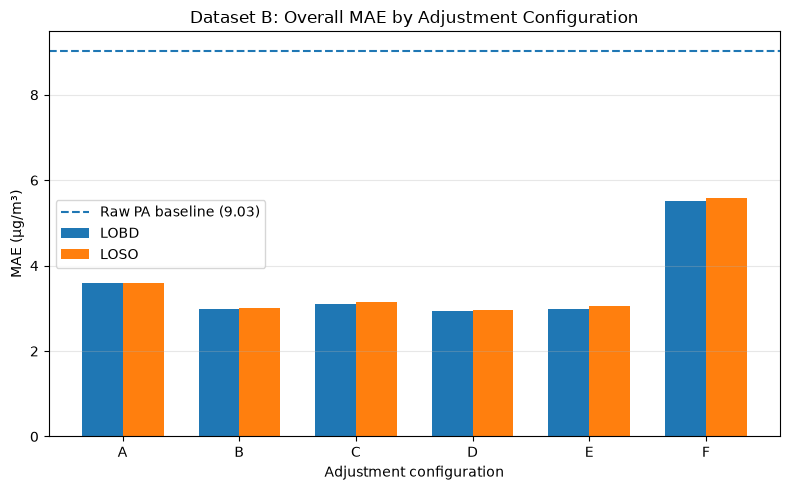

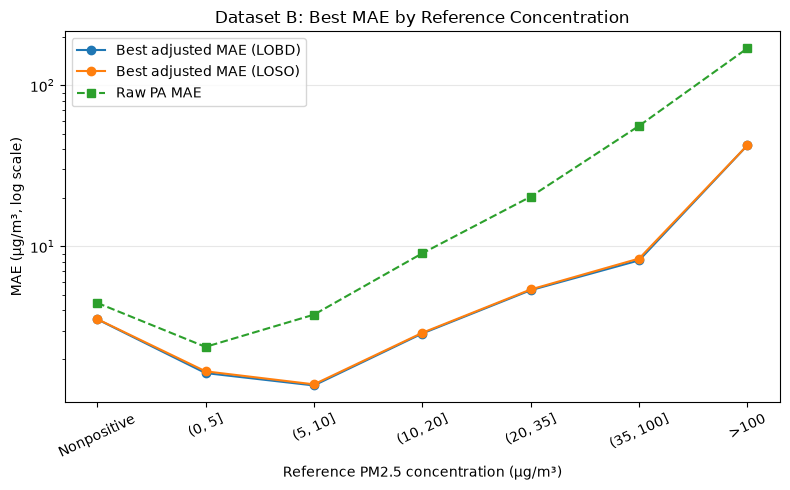

Saved: /Users/nidhi/Desktop/practicum II/low-cost-pm25-calibration/reports/figures/dataset_b_concentration_mae.png


In [61]:

import matplotlib.pyplot as plt
import numpy as np

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Figure 1: Overall MAE comparison
plot_data = smoke_comparison.copy()

adjusted_plot = plot_data[plot_data["adjtype"] != "Raw PA"].copy()

fig, ax = plt.subplots(figsize=(8, 5))

adjustments = ["A", "B", "C", "D", "E", "F"]
x = np.arange(len(adjustments))
width = 0.35

lobd_values = (
    adjusted_plot[adjusted_plot["wholdtype"] == "LOBD"]
    .set_index("adjtype")["MAE"]
    .reindex(adjustments)
)

loso_values = (
    adjusted_plot[adjusted_plot["wholdtype"] == "LOSO"]
    .set_index("adjtype")["MAE"]
    .reindex(adjustments)
)

ax.bar(x - width/2, lobd_values, width, label="LOBD")
ax.bar(x + width/2, loso_values, width, label="LOSO")

raw_mae = plot_data.loc[
    plot_data["adjtype"] == "Raw PA", "MAE"
].iloc[0]

ax.axhline(
    raw_mae,
    linestyle="--",
    label=f"Raw PA baseline ({raw_mae:.2f})"
)

ax.set_title("Dataset B: Overall MAE by Adjustment Configuration")
ax.set_xlabel("Adjustment configuration")
ax.set_ylabel("MAE (µg/m³)")
ax.set_xticks(x)
ax.set_xticklabels(adjustments)
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "dataset_b_overall_mae.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



# Figure 2: Best adjusted MAE versus raw PA by concentration band

concentration_plot = concentration_summary.copy()

# Get raw PA metrics directly from the existing band_metrics table
raw_band = (
    band_metrics[band_metrics["adjtype"] == "Raw PA"]
    [["ref_band", "MAE"]]
    .rename(columns={"MAE": "Raw_MAE"})
    .copy()
)

concentration_plot["ref_band"] = pd.Categorical(
    concentration_plot["ref_band"],
    categories=concentration_labels,
    ordered=True
)

raw_band["ref_band"] = pd.Categorical(
    raw_band["ref_band"],
    categories=concentration_labels,
    ordered=True
)

concentration_plot = concentration_plot.sort_values("ref_band")
raw_band = raw_band.sort_values("ref_band")

fig, ax = plt.subplots(figsize=(8, 5))

for withholding in ["LOBD", "LOSO"]:
    subset = concentration_plot[
        concentration_plot["wholdtype"] == withholding
    ]

    ax.plot(
        subset["ref_band"].astype(str),
        subset["Best_MAE"],
        marker="o",
        label=f"Best adjusted MAE ({withholding})"
    )

ax.plot(
    raw_band["ref_band"].astype(str),
    raw_band["Raw_MAE"],
    marker="s",
    linestyle="--",
    label="Raw PA MAE"
)

ax.set_title("Dataset B: Best MAE by Reference Concentration")
ax.set_xlabel("Reference PM2.5 concentration (µg/m³)")
ax.set_ylabel("MAE (µg/m³)")
ax.tick_params(axis="x", rotation=25)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.set_yscale("log")
ax.set_ylabel("MAE (µg/m³, log scale)")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "dataset_b_concentration_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", FIGURES_DIR / "dataset_b_concentration_mae.png")



## Dataset B: Hourly Wildfire-Smoke Evaluation — Findings

### Evaluation approach

Dataset B contains 126,148 unique city-sensor-hour observations, each represented by six existing adjustment configurations (A–F) and two withholding approaches (LOBD and LOSO). The evaluation compared the provided adjusted measurements (`adj`) with reference measurements (`ref`), using raw PurpleAir measurements (`PA`) as the baseline.

The analysis used MAE, RMSE, mean bias, and R². Configuration comparisons used matched observations. The raw baseline was deduplicated to one row per underlying city-sensor-hour to ensure comparable sample sizes.

### Overall results

All six adjustment configurations reduced pooled MAE compared with raw PA (9.034 µg/m³).

- Configuration D achieved the lowest pooled MAE: 2.928 under LOBD and 2.966 under LOSO.
- Configuration E achieved the lowest pooled RMSE: 10.353 under LOBD and 9.884 under LOSO.
- D reduced pooled MAE by 67.59% under LOBD and 67.17% under LOSO.
- E reduced pooled RMSE by 60.52% under LOBD and 62.31% under LOSO.
- Configurations A and F showed larger systematic bias than the other configurations.

### Sensor-level consistency

All six adjustments improved MAE over raw PA at all 27 city-sensor groups. However, the configuration with the best pooled performance was not necessarily the best at every sensor.

D achieved the most sensor-level MAE wins under LOBD (8 of 27) and tied A under LOSO (7 of 27 each). No configuration won at a majority of sensors.

The mean and median sensor-level results also differed from pooled results because pooled metrics weight sensors according to their observation counts, whereas the sensor-level averages give each sensor equal weight.

### LOBD versus LOSO

The two withholding approaches produced broadly similar overall results, but their differences varied by sensor and metric.

For configurations B–E, LOBD had lower RMSE at 17 of 27 sensors, while LOSO had lower RMSE at 10. The mean RMSE differences favored LOSO because a few sensors showed relatively large improvements. The median differences favored LOBD.

Neither withholding approach was consistently superior across sensors.

### Concentration-dependent performance

Adjustment rankings changed across reference-concentration bands.

- B performed best in the 0–5 µg/m³ range.
- C and D performed best in the 5–10 range, depending on the withholding approach.
- D performed best in the 10–20 and 35–100 ranges.
- E performed best in the 20–35 range and for MAE above 100 under LOBD.
- The nonpositive group had a different ranking, with F achieving the lowest MAE and A the lowest RMSE.

The best adjustment in each concentration band improved on raw PA, but the magnitude varied. The largest best-configuration MAE improvement was approximately 85% in the 35–100 range.

The nonpositive group (4,916 observations) and extreme group above 100 (2,000 observations) require cautious interpretation.

### Interpretation and limitations

Dataset B evaluates existing adjustment outputs; these configurations were not independently trained as new models in this project. The results are descriptive comparisons of the supplied configurations.

The overall results favor D for MAE and E for RMSE, but neither should be described as universally best. Performance depends on the metric, sensor, withholding approach, and reference-concentration range.

Concentration bands are defined using observed reference measurements, so they are useful for retrospective performance analysis, not for selecting an adjustment in advance when the reference value is unknown.
